# ID2223 Lab Assignment 1: CNNs on CIFAR-10

This notebook contains the complete code for the assignment, runs every experiment and produces the tables and figures used in the report. On Colab, select a GPU runtime and use *Run all*; one full run takes about 1.5–2 hours on a T4. Locally, the notebook can be run from the `notebooks/` folder of the repository.

In [1]:
import os, sys
from pathlib import Path

# Work from the repository root (or /content on Colab) and keep the dataset in ./data.
if Path.cwd().name == "notebooks":
    os.chdir("..")
os.environ.setdefault("CIFAR10_DATA_ROOT", str(Path.cwd() / "data"))
Path("src").mkdir(exist_ok=True)
Path("src/__init__.py").touch()
sys.path.insert(0, str(Path.cwd()))
print("Working directory:", Path.cwd())

Working directory: /content


## 1. Implementation

The source files are written to `src/` from the cells below, so the notebook is self-contained. They are identical to the files in the repository.

**`src/config.py`** – Configuration: paths, seed, compute budget and optimiser settings.

In [2]:
%%writefile src/config.py
from pathlib import Path
import os

PROJECT_ROOT = Path(__file__).resolve().parents[1]
DATA_ROOT = Path(os.getenv("CIFAR10_DATA_ROOT", PROJECT_ROOT.parent / "data"))
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
SEED = 2223
BATCH_SIZE = 512
NUM_EPOCHS = 30
LEARNING_RATE = 0.05
MOMENTUM = 0.9
NUM_WORKERS = 0
NUM_CLASSES = 10
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

SEED_STABILITY = [2223, 2224, 2225]

Writing src/config.py


**`src/reproducibility.py`** – Seeding of Python, NumPy and PyTorch, and deterministic cuDNN kernels.

In [3]:
%%writefile src/reproducibility.py
import random
import numpy as np
import torch

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

Writing src/reproducibility.py


**`src/data.py`** – Data split, preprocessing, augmentation and the fixed corrupted test sets.

In [4]:
%%writefile src/data.py
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset, Dataset
from torchvision import datasets, transforms
from .config import DATA_ROOT, BATCH_SIZE, NUM_WORKERS, NUM_CLASSES, MEAN, STD, SEED

class FixedCorruption(Dataset):
    def __init__(self, base, raw_test, kind, seed=SEED): self.base,self.raw,self.kind,self.seed=base,raw_test,kind,seed
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        image,label=self.base[i]
        if self.kind=="noise":
            g=torch.Generator().manual_seed(self.seed+i); image=torch.clamp(image+torch.randn(image.shape,generator=g)*0.20,-3,3)
        elif self.kind=="rotation":
            from PIL import Image
            image=transforms.ToTensor()(transforms.functional.rotate(Image.fromarray(self.raw.data[i]), 15 if i%2==0 else -15))
            image=transforms.Normalize(MEAN,STD)(image)
        return image,label

def balanced_split(targets, fraction=0.1, seed=SEED):
    rng=np.random.default_rng(seed); tr=[]; va=[]; targets=np.asarray(targets)
    for c in range(NUM_CLASSES):
        ids=np.flatnonzero(targets==c); rng.shuffle(ids); n=int(len(ids)*fraction); va+=ids[:n].tolist(); tr+=ids[n:].tolist()
    return sorted(tr),sorted(va)

def build_data():
    basic=transforms.Compose([transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
    augmented=transforms.Compose([transforms.RandomCrop(32,padding=4),transforms.RandomHorizontalFlip(),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
    raw_train=datasets.CIFAR10(str(DATA_ROOT),train=True,download=True); raw_test=datasets.CIFAR10(str(DATA_ROOT),train=False,download=True)
    tr,va=balanced_split(raw_train.targets)
    train_basic=Subset(datasets.CIFAR10(str(DATA_ROOT),train=True,transform=basic,download=True),tr)
    train_aug=Subset(datasets.CIFAR10(str(DATA_ROOT),train=True,transform=augmented,download=True),tr)
    val=Subset(datasets.CIFAR10(str(DATA_ROOT),train=True,transform=basic,download=True),va)
    test=datasets.CIFAR10(str(DATA_ROOT),train=False,transform=basic,download=True)
    loaders=lambda ds,sh: DataLoader(ds,batch_size=BATCH_SIZE,shuffle=sh,num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available())
    return {"raw_train":raw_train,"raw_test":raw_test,"train_basic":loaders(train_basic,True),"train_aug":loaders(train_aug,True),"val":loaders(val,False),"test":loaders(test,False),"noise":loaders(FixedCorruption(test,raw_test,"noise"),False),"rotation":loaders(FixedCorruption(test,raw_test,"rotation"),False)}

Writing src/data.py


**`src/models.py`** – The two architectures and the width/dropout options used in Task 3.

In [5]:
%%writefile src/models.py
"""AlexNet and ResNet variants for 32x32 CIFAR-10 inputs (Lab 2, Part A9)."""

import torch
import torch.nn as nn


class CIFAR10AlexNet(nn.Module):
    """AlexNet adapted for 32x32 CIFAR-10 images."""

    def __init__(self, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, 1, 1), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 192, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(192, 384, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
        )
        # 256 x 4 x 4 = 4096 flattened features -> 1024 -> 512 -> 10.
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(256 * 4 * 4, 1024), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(1024, 512), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class BasicBlock(nn.Module):
    """Basic residual block: two 3x3 convolutions plus an identity or 1x1 projection shortcut."""

    def __init__(self, cin, cout, stride=1, dropout=0.0):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.b2 = nn.BatchNorm2d(cout)
        self.d = nn.Dropout2d(dropout) if dropout else nn.Identity()
        self.s = nn.Identity() if stride == 1 and cin == cout else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout)
        )

    def forward(self, x):
        y = torch.relu(self.b1(self.c1(x)))
        y = self.d(y)
        y = self.b2(self.c2(y))
        return torch.relu(y + self.s(x))


class CIFAR10ResNet(nn.Module):
    """ResNet-18 layout with a 3x3 stem and no initial max-pooling, as used for CIFAR-10."""

    def __init__(self, base_width=64, dropout=0.0):
        super().__init__()
        self.in_c = base_width
        self.stem = nn.Sequential(
            nn.Conv2d(3, base_width, 3, padding=1, bias=False),
            nn.BatchNorm2d(base_width), nn.ReLU(inplace=True),
        )
        self.s1 = self.stage(base_width, 2, 1, dropout)
        self.s2 = self.stage(base_width * 2, 2, 2, dropout)
        self.s3 = self.stage(base_width * 4, 2, 2, dropout)
        self.s4 = self.stage(base_width * 8, 2, 2, dropout)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.d = nn.Dropout(dropout)
        self.fc = nn.Linear(base_width * 8, 10)

    def stage(self, out, n, stride, dropout):
        blocks = [BasicBlock(self.in_c, out, stride, dropout)]
        self.in_c = out
        blocks += [BasicBlock(out, out, 1, dropout) for _ in range(n - 1)]
        return nn.Sequential(*blocks)

    def forward(self, x):
        x = self.stem(x)
        x = self.s1(x)
        x = self.s2(x)
        x = self.s3(x)
        x = self.s4(x)
        return self.fc(self.d(self.pool(x).flatten(1)))


def parameter_count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

Writing src/models.py


**`src/training.py`** – Training loop with validation-based checkpoint selection, evaluation and the inference benchmark.

In [6]:
%%writefile src/training.py
import time
from copy import deepcopy
import torch
import torch.nn as nn
import torch.optim as optim
from .config import LEARNING_RATE, MOMENTUM, NUM_EPOCHS

def evaluate(model, loader, device):
    model.eval(); loss_fn = nn.CrossEntropyLoss(); loss_sum = correct = total = 0; predictions = []; labels_all = []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images); loss = loss_fn(logits, labels)
            loss_sum += loss.item() * len(labels); correct += (logits.argmax(1) == labels).sum().item(); total += len(labels)
            predictions.append(logits.argmax(1).cpu()); labels_all.append(labels.cpu())
    return loss_sum / total, correct / total, torch.cat(predictions).numpy(), torch.cat(labels_all).numpy()

def fit(model, train_loader, validation_loader, device, name, weight_decay=0.0, epochs=NUM_EPOCHS):
    model.to(device)
    amp_enabled = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss(); best_accuracy = -1.0; best_state = None; history = []; start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train(); loss_sum = correct = total = 0; epoch_start = time.perf_counter()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device); optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
                logits = model(images); loss = loss_fn(logits, labels)
            if amp_enabled:
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            else:
                loss.backward(); optimizer.step()
            loss_sum += loss.item() * len(labels); correct += (logits.argmax(1) == labels).sum().item(); total += len(labels)
        validation_loss, validation_accuracy, _, _ = evaluate(model, validation_loader, device); scheduler.step()
        train_accuracy = correct / total
        history.append({"epoch": epoch, "train_loss": loss_sum / total, "train_accuracy": train_accuracy, "validation_loss": validation_loss, "validation_accuracy": validation_accuracy, "seconds": time.perf_counter() - epoch_start})
        print(f"{name} epoch {epoch}/{epochs} train={train_accuracy:.3f} val={validation_accuracy:.3f}", flush=True)
        if validation_accuracy > best_accuracy:
            best_accuracy = validation_accuracy; best_state = deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, history, {"name": name, "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad), "training_seconds": time.perf_counter() - start, "best_validation_accuracy": best_accuracy}

def benchmark_inference(model, loader, device, warmup=5, repeats=20):
    """Forward-pass throughput on one test batch that is already on the device.

    Data loading is excluded, the model runs in eval mode with float32 weights,
    and the first `warmup` passes are not timed.
    """
    model.eval()
    images, _ = next(iter(loader))
    images = images.to(device)

    def sync():
        if device.type == "cuda":
            torch.cuda.synchronize()

    with torch.no_grad():
        for _ in range(warmup):
            model(images)
        sync()
        start = time.perf_counter()
        for _ in range(repeats):
            model(images)
        sync()
    elapsed = time.perf_counter() - start
    ms_per_batch = 1000 * elapsed / repeats
    return {"inference_ms_per_batch": ms_per_batch,
            "inference_images_per_second": len(images) * repeats / elapsed}

Writing src/training.py


**`src/evaluation.py`** – Classification report and confusion matrix.

In [7]:
%%writefile src/evaluation.py
import numpy as np
from sklearn.metrics import confusion_matrix,classification_report

def per_class_accuracy(pred,truth,n=10):
    return [float((pred[truth==c]==c).mean()) for c in range(n)]

def report(pred,truth,names):
    return classification_report(truth,pred,target_names=names,digits=3),confusion_matrix(truth,pred)

Writing src/evaluation.py


**`src/robustness.py`** – Clean vs. corrupted evaluation (Task 4).

In [8]:
%%writefile src/robustness.py
from .training import evaluate
from .config import NUM_CLASSES


def per_class(pred, truth):
    return [float((pred[truth == c] == c).mean()) for c in range(NUM_CLASSES)]


def compare(model_a, model_b, loaders, device):
    """Evaluate two models on the same clean, noisy and rotated test images."""
    rows, class_rows, predictions = [], [], {}
    for name, model in [("ResNet basic", model_a), ("ResNet augmented", model_b)]:
        row = {"name": name}
        predictions[name] = {}
        for split in ("test", "noise", "rotation"):
            _, accuracy, pred, truth = evaluate(model, loaders[split], device)
            key = "clean" if split == "test" else split
            row[f"{key}_accuracy"] = accuracy
            predictions[name][key] = pred.tolist()
            for c, value in enumerate(per_class(pred, truth)):
                class_rows.append({"name": name, "condition": key, "class": c, "accuracy": value})
        row["noise_drop"] = row["clean_accuracy"] - row["noise_accuracy"]
        row["rotation_drop"] = row["clean_accuracy"] - row["rotation_accuracy"]
        rows.append(row)
    predictions["truth"] = truth.tolist()
    return rows, class_rows, predictions

Writing src/robustness.py


**`src/adversarial.py`** – FGSM attack (Task 5).

In [9]:
%%writefile src/adversarial.py
import torch
import torch.nn.functional as F
from .config import MEAN, STD


def _stats(device):
    mean = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=device).view(1, 3, 1, 1)
    return mean, std


def fgsm(model, images, labels, device, epsilon=4 / 255):
    """One-step FGSM with an L-infinity budget measured in [0, 1] pixel units.

    The inputs are normalised tensors. The step is taken in pixel space and the
    result is clipped to [0, 1] before it is normalised again, so the adversarial
    image is always a valid image.
    """
    model.eval()
    mean, std = _stats(device)
    x = images.clone().detach().to(device).requires_grad_(True)
    y = labels.to(device)
    loss = F.cross_entropy(model(x), y)
    grad, = torch.autograd.grad(loss, x)
    # std > 0, so the sign of the pixel-space gradient equals the sign of grad.
    pixels = x.detach() * std + mean
    adv_pixels = (pixels + epsilon * grad.sign()).clamp(0, 1)
    return ((adv_pixels - mean) / std).detach()


def to_pixels(images, device):
    mean, std = _stats(device)
    return (images.to(device) * std + mean).clamp(0, 1)


def attack_success_rate(model, loader, device, epsilon, max_images=2000):
    """Share of correctly classified test images whose label flips under FGSM."""
    model.eval()
    attacked = flipped = seen = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        with torch.no_grad():
            clean = model(images).argmax(1)
        keep = clean == labels
        if keep.any():
            adv = fgsm(model, images[keep], labels[keep], device, epsilon)
            with torch.no_grad():
                flipped += (model(adv).argmax(1) != labels[keep]).sum().item()
            attacked += int(keep.sum())
        seen += len(labels)
        if seen >= max_images:
            break
    return {"epsilon": epsilon, "attacked": attacked, "flipped": flipped,
            "success_rate": flipped / max(attacked, 1)}

Writing src/adversarial.py


**`src/experiments.py`** – The full experiment schedule. Every configuration is trained once with the same seed and budget.

In [10]:
%%writefile src/experiments.py
import json
import platform
import numpy as np
import pandas as pd
import torch
from .config import SEED, NUM_EPOCHS, OUTPUT_ROOT, CLASS_NAMES, BATCH_SIZE, LEARNING_RATE, MOMENTUM
from .reproducibility import set_seed
from .models import CIFAR10AlexNet, CIFAR10ResNet
from .training import fit, evaluate, benchmark_inference
from .robustness import compare
from .adversarial import fgsm, to_pixels, attack_success_rate
from .data import build_data
from .evaluation import report

EPSILONS = [1 / 255, 2 / 255, 4 / 255, 8 / 255]


def run_info(device):
    info = {"device": str(device), "torch": torch.__version__, "python": platform.python_version(),
            "seed": SEED, "epochs": NUM_EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
            "momentum": MOMENTUM, "optimizer": "SGD + cosine annealing", "mixed_precision": device.type == "cuda"}
    if device.type == "cuda":
        info["gpu"] = torch.cuda.get_device_name(0)
    return info


def adversarial_example(model, data, device):
    """Attack the first correctly classified test image with the smallest budget that flips it."""
    images, labels = next(iter(data["test"]))
    images, labels = images.to(device), labels.to(device)
    with torch.no_grad():
        clean_pred = model(images).argmax(1)
    index = int((clean_pred == labels).nonzero()[0])
    x, y = images[index:index + 1], labels[index:index + 1]
    for epsilon in EPSILONS:
        adv = fgsm(model, x, y, device, epsilon)
        with torch.no_grad():
            clean_prob = torch.softmax(model(x), 1)[0]
            adv_prob = torch.softmax(model(adv), 1)[0]
        if adv_prob.argmax().item() != y.item():
            break
    np.savez_compressed(OUTPUT_ROOT / "metrics" / "adversarial_example.npz",
                        clean=to_pixels(x, device)[0].cpu().numpy(), adversarial=to_pixels(adv, device)[0].cpu().numpy())
    return {"method": "FGSM (single step, L-infinity, pixel space)", "epsilon": epsilon,
            "epsilon_in_255": round(epsilon * 255), "test_index": index,
            "true_label": int(y), "original_prediction": int(clean_prob.argmax()),
            "original_confidence": float(clean_prob.max()),
            "adversarial_prediction": int(adv_prob.argmax()), "adversarial_confidence": float(adv_prob.max()),
            "attack_success": bool(adv_prob.argmax().item() != y.item())}


def run_all():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    metrics = OUTPUT_ROOT / "metrics"
    metrics.mkdir(parents=True, exist_ok=True)
    OUTPUT_ROOT.joinpath("checkpoints").mkdir(parents=True, exist_ok=True)
    (metrics / "run_info.json").write_text(json.dumps(run_info(device), indent=2), encoding="utf-8")
    set_seed(SEED)
    data = build_data()
    results, histories, models, predictions = [], {}, {}, {}

    def run(name, build_model, loader, weight_decay=0.0):
        # Seed before the model is built so that every configuration starts from
        # the same random state (same initial weights for identical architectures).
        set_seed(SEED)
        model = build_model()
        trained, history, info = fit(model, loader, data["val"], device, name, weight_decay, NUM_EPOCHS)
        test_loss, test_accuracy, pred, truth = evaluate(trained, data["test"], device)
        info.update({"test_loss": test_loss, "test_accuracy": test_accuracy, "weight_decay": weight_decay,
                     "seconds_per_epoch": info["training_seconds"] / NUM_EPOCHS})
        info.update(benchmark_inference(trained, data["test"], device))
        results.append(info); histories[name] = history; models[name] = trained
        predictions[name] = {"pred": pred.tolist(), "truth": truth.tolist()}
        torch.save(trained.state_dict(), OUTPUT_ROOT / "checkpoints" / (name.replace(" ", "_") + ".pt"))
        pd.DataFrame(results).to_csv(metrics / "model_results.csv", index=False)
        (metrics / "histories.json").write_text(json.dumps(histories), encoding="utf-8")
        return trained

    alex = run("AlexNet baseline", CIFAR10AlexNet, data["train_basic"])
    base = run("ResNet baseline", CIFAR10ResNet, data["train_basic"])
    run("ResNet width 16", lambda: CIFAR10ResNet(base_width=16), data["train_basic"])
    run("ResNet width 32", lambda: CIFAR10ResNet(base_width=32), data["train_basic"])
    run("ResNet dropout 0.3", lambda: CIFAR10ResNet(dropout=0.3), data["train_basic"])
    run("ResNet dropout 0.5", lambda: CIFAR10ResNet(dropout=0.5), data["train_basic"])
    run("ResNet L2", CIFAR10ResNet, data["train_basic"], 1e-4)
    augmented = run("ResNet augmented", CIFAR10ResNet, data["train_aug"])

    robust_rows, robust_class_rows, robust_predictions = compare(base, augmented, data, device)
    report_text, confusion = report(np.array(predictions["ResNet augmented"]["pred"]),
                                    np.array(predictions["ResNet augmented"]["truth"]), CLASS_NAMES)

    rates = []
    for name, model in [("AlexNet baseline", alex), ("ResNet baseline", base), ("ResNet augmented", augmented)]:
        for epsilon in EPSILONS:
            row = attack_success_rate(model, data["test"], device, epsilon)
            row.update({"name": name, "epsilon_in_255": round(epsilon * 255)})
            rates.append(row)
    adv_info = adversarial_example(augmented, data, device)

    model_df = pd.DataFrame(results)
    robust_df = pd.DataFrame(robust_rows)
    model_df.to_csv(metrics / "model_results.csv", index=False)
    robust_df.to_csv(metrics / "robustness_results.csv", index=False)
    pd.DataFrame(robust_class_rows).to_csv(metrics / "robustness_per_class.csv", index=False)
    pd.DataFrame(rates).to_csv(metrics / "adversarial_rates.csv", index=False)
    (metrics / "robustness_predictions.json").write_text(json.dumps(robust_predictions), encoding="utf-8")
    (metrics / "predictions.json").write_text(json.dumps(predictions), encoding="utf-8")
    (metrics / "classification_report.txt").write_text(report_text, encoding="utf-8")
    (metrics / "confusion_matrix.csv").write_text(pd.DataFrame(confusion, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv())
    (metrics / "adversarial_result.json").write_text(json.dumps(adv_info, indent=2), encoding="utf-8")
    print(model_df.to_string(index=False)); print(robust_df.to_string(index=False))
    print(pd.DataFrame(rates).to_string(index=False)); print(adv_info)
    return {"device": str(device), "models": model_df, "robustness": robust_df, "adversarial": adv_info}

Writing src/experiments.py


## 2. Run all experiments

This trains eight configurations for 30 epochs each and writes the results to `outputs/metrics/`. The per-epoch log below is the training record for every number in the report.

In [11]:
from src.experiments import run_all
results = run_all()

100%|██████████| 170M/170M [00:18<00:00, 9.27MB/s]


AlexNet baseline epoch 1/30 train=0.138 val=0.192
AlexNet baseline epoch 2/30 train=0.267 val=0.314
AlexNet baseline epoch 3/30 train=0.381 val=0.436
AlexNet baseline epoch 4/30 train=0.472 val=0.521
AlexNet baseline epoch 5/30 train=0.552 val=0.591
AlexNet baseline epoch 6/30 train=0.618 val=0.662
AlexNet baseline epoch 7/30 train=0.676 val=0.689
AlexNet baseline epoch 8/30 train=0.713 val=0.716
AlexNet baseline epoch 9/30 train=0.749 val=0.742
AlexNet baseline epoch 10/30 train=0.778 val=0.755
AlexNet baseline epoch 11/30 train=0.801 val=0.775
AlexNet baseline epoch 12/30 train=0.832 val=0.789
AlexNet baseline epoch 13/30 train=0.856 val=0.787
AlexNet baseline epoch 14/30 train=0.871 val=0.804
AlexNet baseline epoch 15/30 train=0.897 val=0.795
AlexNet baseline epoch 16/30 train=0.911 val=0.812
AlexNet baseline epoch 17/30 train=0.933 val=0.815
AlexNet baseline epoch 18/30 train=0.949 val=0.815
AlexNet baseline epoch 19/30 train=0.963 val=0.814
AlexNet baseline epoch 20/30 train=0.972

In [12]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.config import CLASS_NAMES, OUTPUT_ROOT, MEAN, STD, NUM_EPOCHS
from src.data import build_data
from src.models import CIFAR10AlexNet, CIFAR10ResNet

metrics = OUTPUT_ROOT / "metrics"
model_results = pd.read_csv(metrics / "model_results.csv").set_index("name")
histories = json.loads((metrics / "histories.json").read_text())
robustness = pd.read_csv(metrics / "robustness_results.csv").set_index("name")
robust_class = pd.read_csv(metrics / "robustness_per_class.csv")
robust_pred = json.loads((metrics / "robustness_predictions.json").read_text())
predictions = json.loads((metrics / "predictions.json").read_text())
adv_rates = pd.read_csv(metrics / "adversarial_rates.csv")
adversarial = json.loads((metrics / "adversarial_result.json").read_text())
run_info = json.loads((metrics / "run_info.json").read_text())
data = build_data()
pd.set_option("display.precision", 4)
print(json.dumps(run_info, indent=2))

{
  "device": "cuda",
  "torch": "2.14.1+cu130",
  "python": "3.13.16",
  "seed": 2223,
  "epochs": 30,
  "batch_size": 512,
  "learning_rate": 0.05,
  "momentum": 0.9,
  "optimizer": "SGD + cosine annealing",
  "mixed_precision": true,
  "gpu": "Tesla T4"
}


## Task 1. Data

Each CIFAR-10 example is a 32×32 RGB photograph with one of ten object labels. The official training set (50,000 images) is split into 45,000 training and 5,000 validation images, 10% of each class, with a fixed NumPy generator. The 10,000 test images are only used after a checkpoint has been chosen on the validation set.

,train,validation,test
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000
truck,4500,500,1000


Overlap between train and validation indices: 0


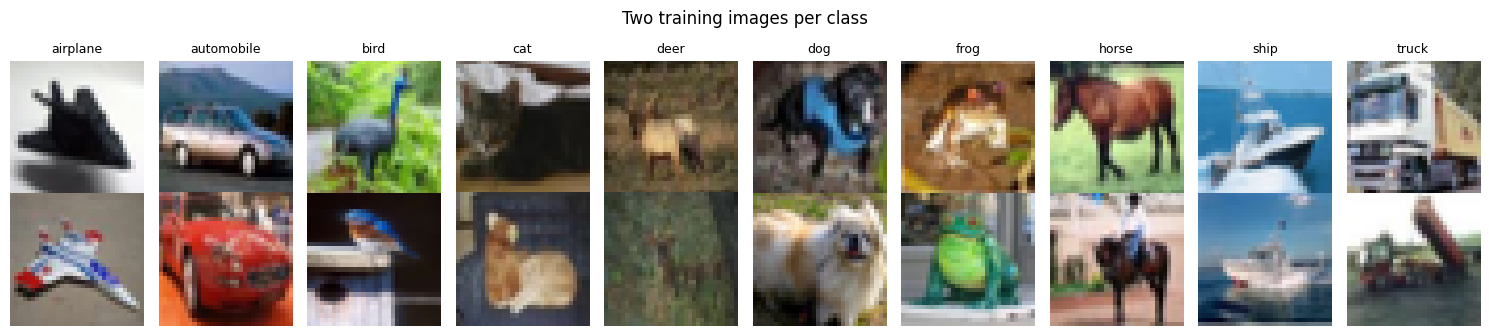

In [13]:
raw_train, raw_test = data["raw_train"], data["raw_test"]
train_idx = data["train_basic"].dataset.indices
val_idx = data["val"].dataset.indices
targets = np.array(raw_train.targets)
counts = pd.DataFrame({
    "train": np.bincount(targets[train_idx], minlength=10),
    "validation": np.bincount(targets[val_idx], minlength=10),
    "test": np.bincount(np.array(raw_test.targets), minlength=10),
}, index=CLASS_NAMES)
display(counts)
print("Overlap between train and validation indices:", len(set(train_idx) & set(val_idx)))

fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for c in range(10):
    for row in range(2):
        idx = np.flatnonzero(targets == c)[row]
        axes[row, c].imshow(raw_train.data[idx]); axes[row, c].axis("off")
    axes[0, c].set_title(CLASS_NAMES[c], fontsize=9)
plt.suptitle("Two training images per class"); plt.tight_layout(); plt.show()

In [14]:
# The normalisation constants should match the statistics of the training split.
pixels = raw_train.data[train_idx].astype(np.float32) / 255
print("Training-split channel mean:", pixels.mean(axis=(0, 1, 2)).round(4), " used:", MEAN)
print("Training-split channel std: ", pixels.std(axis=(0, 1, 2)).round(4), " used:", STD)
print("Batches per epoch - train:", len(data["train_basic"]), "val:", len(data["val"]), "test:", len(data["test"]))

Training-split channel mean: [0.4915 0.4823 0.4467]  used: (0.4914, 0.4822, 0.4465)
Training-split channel std:  [0.2468 0.2434 0.2615]  used: (0.247, 0.2435, 0.2616)
Batches per epoch - train: 88 val: 10 test: 20


Both architectures receive the same input: the image is converted to a float tensor in [0, 1] and normalised per channel. No resizing is needed because both networks are adapted to 32×32 inputs. The augmented condition in Task 4 adds a random 32×32 crop from a 4-pixel zero-padded image and a random horizontal flip, applied to the training split only.

Randomness is controlled by `set_seed`, which seeds Python, NumPy and PyTorch and makes cuDNN deterministic. The seed is reset before every model is created, so the initial weights, the shuffling order and the augmentation draws are the same for every configuration that shares an architecture. Data loading runs in the main process, so no worker seeding is needed. Mixed-precision kernels on the GPU are still not guaranteed to be bit-for-bit identical across hardware.

## Task 2. AlexNet and ResNet

The tables list every layer with its output shape for one 32×32 input and its number of trainable parameters.

In [15]:
import torch

def layer_table(model):
    rows, hooks = [], []
    leaves = (torch.nn.Conv2d, torch.nn.Linear, torch.nn.MaxPool2d, torch.nn.AdaptiveAvgPool2d, torch.nn.BatchNorm2d)
    for name, module in model.named_modules():
        if isinstance(module, leaves):
            def hook(m, i, o, name=name):
                rows.append({"layer": name, "type": m.__class__.__name__, "output": tuple(o.shape[1:]),
                             "parameters": sum(p.numel() for p in m.parameters())})
            hooks.append(module.register_forward_hook(hook))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, 32, 32))
    for h in hooks:
        h.remove()
    return pd.DataFrame(rows)

alex_table = layer_table(CIFAR10AlexNet())
display(alex_table)
print("AlexNet total:", alex_table.parameters.sum())

,layer,type,output,parameters
0,features.0,Conv2d,"(64, 32, 32)",1792
1,features.2,MaxPool2d,"(64, 16, 16)",0
2,features.3,Conv2d,"(192, 16, 16)",110784
3,features.5,MaxPool2d,"(192, 8, 8)",0
4,features.6,Conv2d,"(384, 8, 8)",663936
5,features.8,Conv2d,"(256, 8, 8)",884992
6,features.10,Conv2d,"(256, 8, 8)",590080
7,features.12,MaxPool2d,"(256, 4, 4)",0
8,classifier.1,Linear,"(1024,)",4195328
9,classifier.4,Linear,"(512,)",524800


AlexNet total: 6976842


In [16]:
resnet_table = layer_table(CIFAR10ResNet())
resnet_table["stage"] = resnet_table.layer.str.split(".").str[0]
summary = resnet_table.groupby("stage", sort=False).agg(output=("output", "last"), parameters=("parameters", "sum"))
display(summary)
print("ResNet total:", resnet_table.parameters.sum())
print("Projection shortcuts:", list(resnet_table.layer[resnet_table.layer.str.contains(r"\.s\.0")]))

,output,parameters
stage,,
stem,"(64, 32, 32)",1856
s1,"(64, 32, 32)",147968
s2,"(128, 16, 16)",525568
s3,"(256, 8, 8)",2099712
s4,"(512, 4, 4)",8393728
pool,"(512, 1, 1)",0
fc,"(10,)",5130


ResNet total: 11173962
Projection shortcuts: ['s2.0.s.0', 's3.0.s.0', 's4.0.s.0']


,parameters,best_validation_accuracy,test_accuracy,seconds_per_epoch,training_seconds
name,,,,,
AlexNet baseline,6976842,0.826,0.8204,16.4055,492.1644
ResNet baseline,11173962,0.849,0.8374,28.8664,865.9908


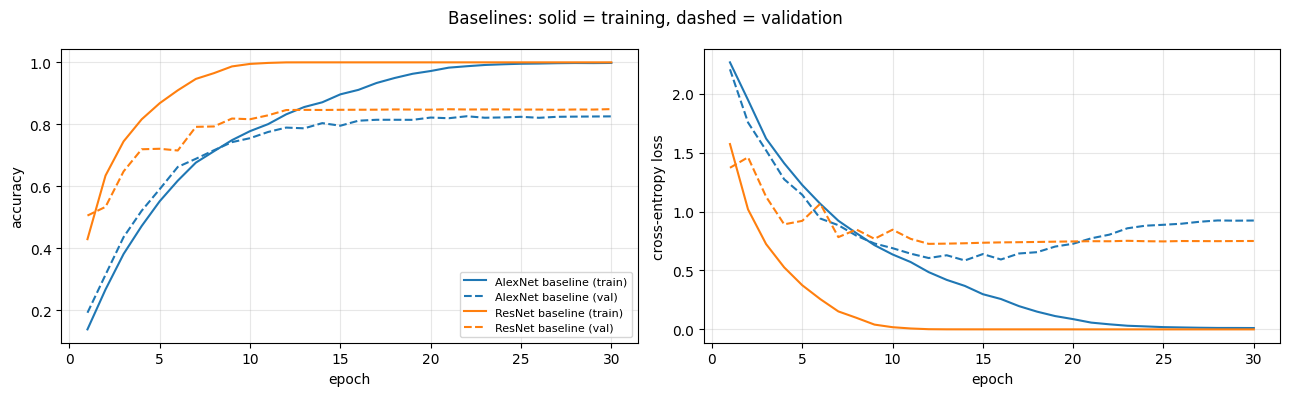

In [17]:
def plot_curves(names, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name in names:
        h = pd.DataFrame(histories[name])
        line, = axes[0].plot(h.epoch, h.train_accuracy, label=f"{name} (train)")
        axes[0].plot(h.epoch, h.validation_accuracy, "--", color=line.get_color(), label=f"{name} (val)")
        axes[1].plot(h.epoch, h.train_loss, color=line.get_color())
        axes[1].plot(h.epoch, h.validation_loss, "--", color=line.get_color())
    axes[0].set_ylabel("accuracy"); axes[1].set_ylabel("cross-entropy loss")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

cols = ["parameters", "best_validation_accuracy", "test_accuracy", "seconds_per_epoch", "training_seconds"]
display(model_results.loc[["AlexNet baseline", "ResNet baseline"], cols])
plot_curves(["AlexNet baseline", "ResNet baseline"], "Baselines: solid = training, dashed = validation")

## Task 3. Capacity and regularisation

Each comparison changes one setting of the ResNet baseline and keeps the data split, seed, optimiser, learning-rate schedule, 30-epoch budget and checkpoint rule fixed. Width scales the channels of all four stages (16, 32, 64 base channels). Dropout is applied after the first convolution of every residual block and before the final linear layer. L2 regularisation is SGD weight decay of 1e-4.

,parameters,best_validation_accuracy,test_accuracy,training_seconds,final_train_accuracy,best_epoch,train_val_gap,min_val_loss_epoch
name,,,,,,,,
ResNet width 16,701466,0.7960,0.7978,486.3430,1.0,23,0.2040,5
ResNet width 32,2797610,0.8116,0.8125,542.7382,1.0,28,0.1884,4
ResNet baseline,11173962,0.8490,0.8374,865.9908,1.0,30,0.1510,12


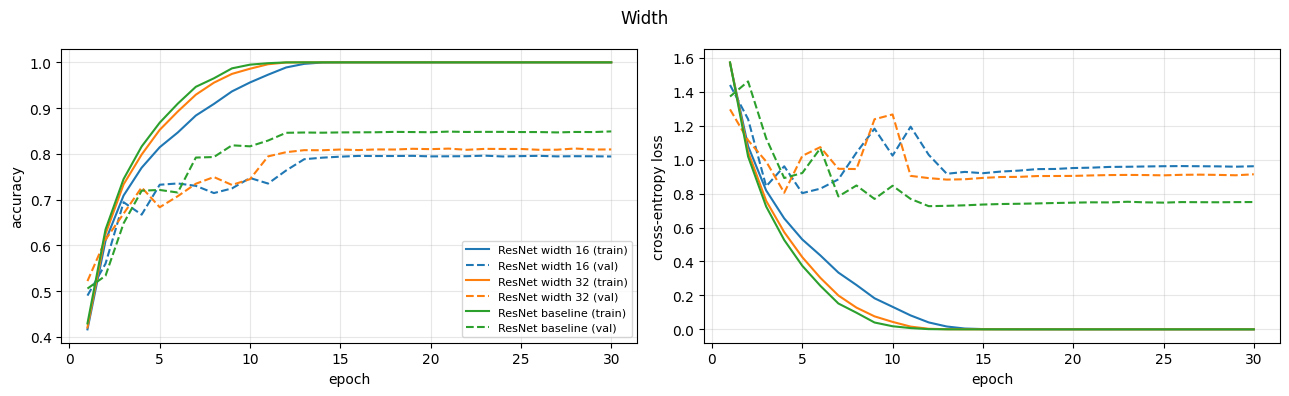

,parameters,best_validation_accuracy,test_accuracy,training_seconds,final_train_accuracy,best_epoch,train_val_gap,min_val_loss_epoch
name,,,,,,,,
ResNet baseline,11173962,0.8490,0.8374,865.9908,1.0000,30,0.1510,12
ResNet dropout 0.3,11173962,0.8422,0.8365,878.8332,0.9930,29,0.1508,11
ResNet dropout 0.5,11173962,0.8220,0.8174,872.7138,0.9191,30,0.0971,18


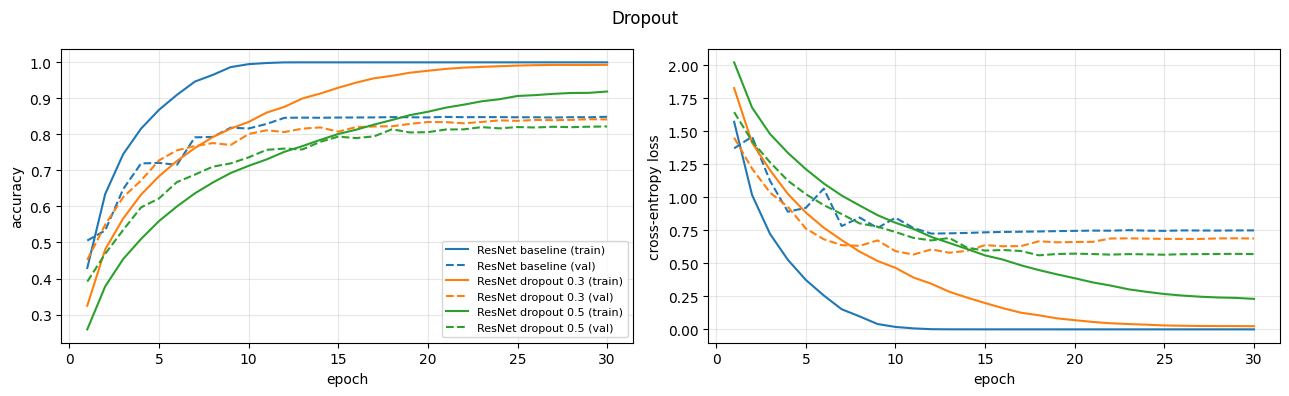

,parameters,best_validation_accuracy,test_accuracy,training_seconds,final_train_accuracy,best_epoch,train_val_gap,min_val_loss_epoch
name,,,,,,,,
ResNet baseline,11173962,0.8490,0.8374,865.9908,1.0,30,0.1510,12
ResNet L2,11173962,0.8424,0.8351,859.8080,1.0,22,0.1576,4


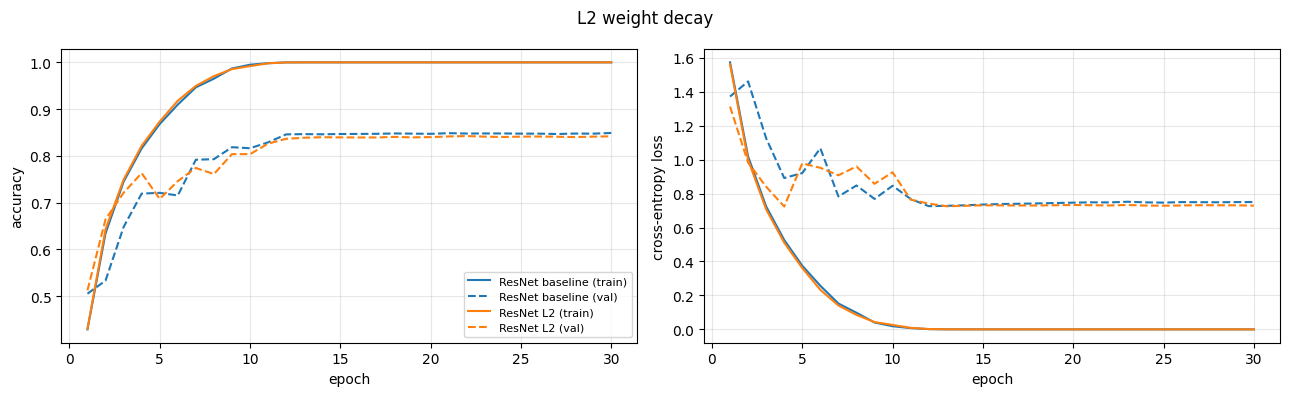

In [18]:
def gap_table(names):
    t = model_results.loc[names, ["parameters", "best_validation_accuracy", "test_accuracy", "training_seconds"]].copy()
    t["final_train_accuracy"] = [histories[n][-1]["train_accuracy"] for n in names]
    t["best_epoch"] = [max(histories[n], key=lambda r: r["validation_accuracy"])["epoch"] for n in names]
    t["train_val_gap"] = t.final_train_accuracy - t.best_validation_accuracy
    t["min_val_loss_epoch"] = [min(histories[n], key=lambda r: r["validation_loss"])["epoch"] for n in names]
    return t

groups = {
    "Width": ["ResNet width 16", "ResNet width 32", "ResNet baseline"],
    "Dropout": ["ResNet baseline", "ResNet dropout 0.3", "ResNet dropout 0.5"],
    "L2 weight decay": ["ResNet baseline", "ResNet L2"],
}
for title, names in groups.items():
    display(gap_table(names))
    plot_curves(names, title)

## Task 4. Robustness and data augmentation

The baseline ResNet (no augmentation) and the augmented ResNet are evaluated on the same three versions of the 10,000 test images:

- **clean** – the original test set;
- **noise** – Gaussian noise with standard deviation 0.2 in normalised units (about 0.05, i.e. 13/255, in pixel units), drawn with a per-image seed so the corrupted set is identical in every run;
- **rotation** – rotation by +15° (even indices) or −15° (odd indices), with black corners.

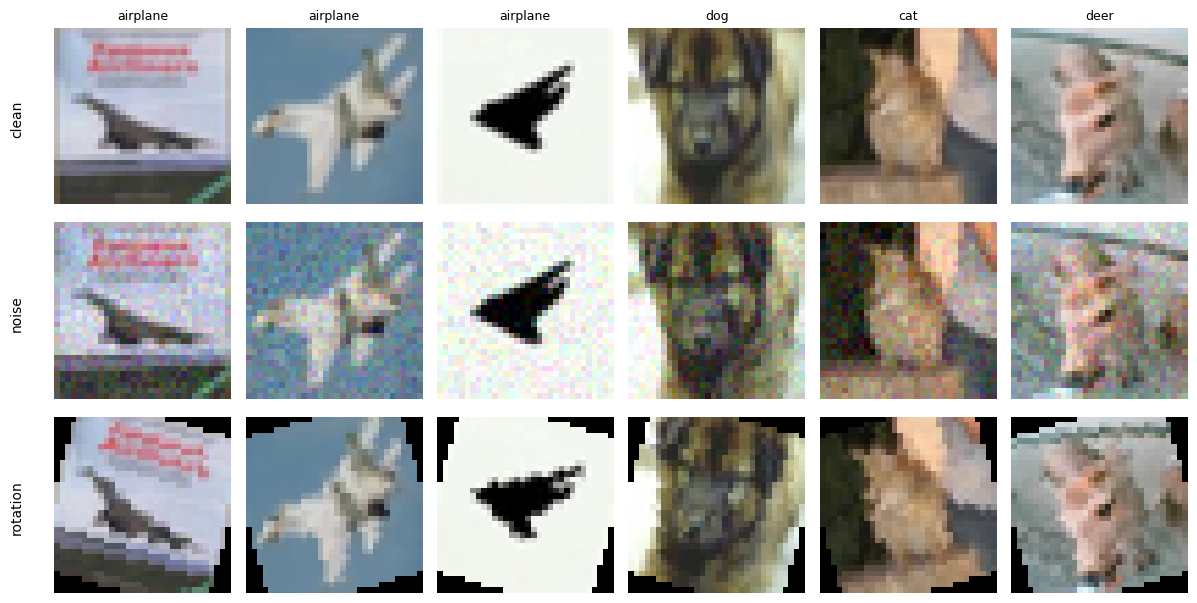

In [19]:
from src.adversarial import to_pixels
show = [3, 10, 21, 33, 46, 58]
sets = {"clean": data["test"].dataset, "noise": data["noise"].dataset, "rotation": data["rotation"].dataset}
fig, axes = plt.subplots(3, len(show), figsize=(12, 6.2))
for r, (label, ds) in enumerate(sets.items()):
    for c, i in enumerate(show):
        img, y = ds[i]
        axes[r, c].imshow(to_pixels(img.unsqueeze(0), torch.device("cpu"))[0].permute(1, 2, 0).numpy())
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(CLASS_NAMES[y], fontsize=9)
    axes[r, 0].text(-6, 16, label, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

,clean_accuracy,noise_accuracy,rotation_accuracy,noise_drop,rotation_drop
name,,,,,
ResNet basic,0.8374,0.7733,0.6588,0.0641,0.1786
ResNet augmented,0.9037,0.7228,0.7180,0.1809,0.1857


,training_seconds,seconds_per_epoch
name,,
ResNet baseline,865.9908,28.8664
ResNet augmented,1057.6170,35.2539


name       ResNet augmented                 ResNet basic                
condition             clean  noise rotation        clean  noise rotation
airplane              0.919  0.504    0.771        0.868  0.721    0.643
automobile            0.958  0.768    0.631        0.918  0.852    0.741
bird                  0.857  0.794    0.651        0.755  0.668    0.605
cat                   0.816  0.618    0.589        0.668  0.528    0.553
deer                  0.912  0.783    0.750        0.816  0.816    0.627
dog                   0.845  0.484    0.596        0.757  0.615    0.587
frog                  0.915  0.951    0.941        0.875  0.939    0.889
horse                 0.918  0.584    0.746        0.882  0.789    0.658
ship                  0.954  0.862    0.775        0.917  0.900    0.672
truck                 0.943  0.880    0.730        0.918  0.905    0.613

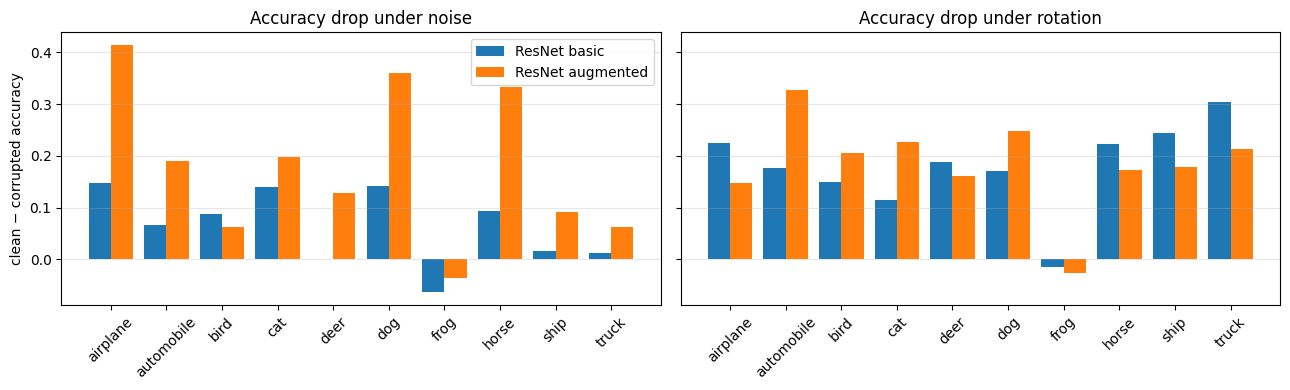

In [20]:
display(robustness)
display(model_results.loc[["ResNet baseline", "ResNet augmented"], ["training_seconds", "seconds_per_epoch"]])

per_class = robust_class.pivot_table(index="class", columns=["name", "condition"], values="accuracy")
per_class.index = CLASS_NAMES
display(per_class)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, cond in zip(axes, ["noise", "rotation"]):
    for k, name in enumerate(["ResNet basic", "ResNet augmented"]):
        drop = per_class[(name, "clean")] - per_class[(name, cond)]
        ax.bar(np.arange(10) + (k - 0.5) * 0.4, drop, width=0.4, label=name)
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45)
    ax.set_title(f"Accuracy drop under {cond}"); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("clean − corrupted accuracy"); axes[0].legend()
plt.tight_layout(); plt.show()

In [21]:
# Which errors does each corruption add? Count (true, predicted) pairs that are
# wrong on the corrupted image but correct on the clean one.
truth = np.array(robust_pred["truth"])
for name in ["ResNet basic", "ResNet augmented"]:
    clean = np.array(robust_pred[name]["clean"])
    for cond in ["noise", "rotation"]:
        corrupted = np.array(robust_pred[name][cond])
        new_errors = (clean == truth) & (corrupted != truth)
        pairs = pd.Series([f"{CLASS_NAMES[t]} -> {CLASS_NAMES[p]}" for t, p in zip(truth[new_errors], corrupted[new_errors])])
        predicted = pd.Series(corrupted[new_errors]).map(dict(enumerate(CLASS_NAMES))).value_counts()
        print(f"{name}, {cond}: {new_errors.sum()} new errors, {((clean != truth) & (corrupted == truth)).sum()} fixed")
        print("  most frequent new errors:", pairs.value_counts().head(5).to_dict())
        print("  predicted class of new errors:", predicted.head(4).to_dict())

ResNet basic, noise: 960 new errors, 319 fixed
  most frequent new errors: {'cat -> frog': 79, 'bird -> frog': 68, 'horse -> deer': 55, 'cat -> deer': 49, 'dog -> deer': 44}
  predicted class of new errors: {'frog': 286, 'deer': 243, 'truck': 94, 'bird': 85}
ResNet basic, rotation: 2178 new errors, 392 fixed
  most frequent new errors: {'dog -> cat': 121, 'truck -> frog': 94, 'deer -> frog': 80, 'automobile -> frog': 80, 'ship -> airplane': 73}
  predicted class of new errors: {'frog': 569, 'cat': 460, 'bird': 260, 'dog': 202}
ResNet augmented, noise: 2038 new errors, 229 fixed
  most frequent new errors: {'airplane -> bird': 170, 'horse -> deer': 165, 'cat -> frog': 134, 'dog -> cat': 122, 'dog -> frog': 110}
  predicted class of new errors: {'frog': 538, 'bird': 463, 'deer': 406, 'cat': 282}
ResNet augmented, rotation: 2093 new errors, 236 fixed
  most frequent new errors: {'automobile -> frog': 130, 'cat -> frog': 121, 'dog -> cat': 114, 'bird -> frog': 89, 'ship -> airplane': 84}
 

## Task 5. Predictions and adversarial examples

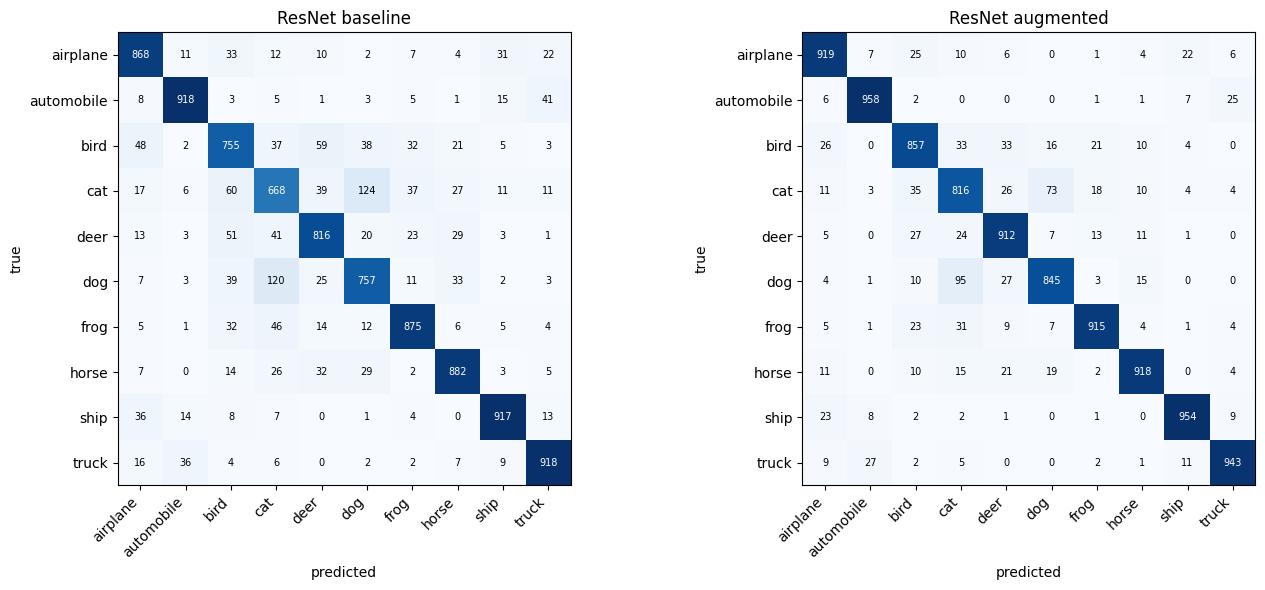

ResNet augmented:
              precision    recall  f1-score   support

    airplane      0.902     0.919     0.910      1000
  automobile      0.953     0.958     0.956      1000
        bird      0.863     0.857     0.860      1000
         cat      0.791     0.816     0.804      1000
        deer      0.881     0.912     0.896      1000
         dog      0.874     0.845     0.859      1000
        frog      0.937     0.915     0.926      1000
       horse      0.943     0.918     0.930      1000
        ship      0.950     0.954     0.952      1000
       truck      0.948     0.943     0.945      1000

    accuracy                          0.904     10000
   macro avg      0.904     0.904     0.904     10000
weighted avg      0.904     0.904     0.904     10000



,AlexNet baseline,ResNet baseline,ResNet augmented
airplane,0.8333,0.8573,0.9104
automobile,0.9071,0.9208,0.9556
bird,0.7417,0.7554,0.8600
cat,0.6660,0.6789,0.8035
deer,0.8002,0.8176,0.8963
dog,0.7466,0.7616,0.8592
frog,0.8652,0.8759,0.9256
horse,0.8644,0.8776,0.9301
ship,0.8949,0.9165,0.9521
truck,0.8797,0.9085,0.9454


In [22]:
from sklearn.metrics import confusion_matrix, classification_report
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["ResNet baseline", "ResNet augmented"]):
    p, t = np.array(predictions[name]["pred"]), np.array(predictions[name]["truth"])
    cm = confusion_matrix(t, p)
    ax.imshow(cm, cmap="Blues")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 500 else "black")
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(name)
plt.tight_layout(); plt.show()
print("ResNet augmented:")
print((metrics / "classification_report.txt").read_text())

f1 = {}
for name in ["AlexNet baseline", "ResNet baseline", "ResNet augmented"]:
    rep = classification_report(predictions[name]["truth"], predictions[name]["pred"], output_dict=True)
    f1[name] = [rep[str(c)]["f1-score"] for c in range(10)]
display(pd.DataFrame(f1, index=CLASS_NAMES))

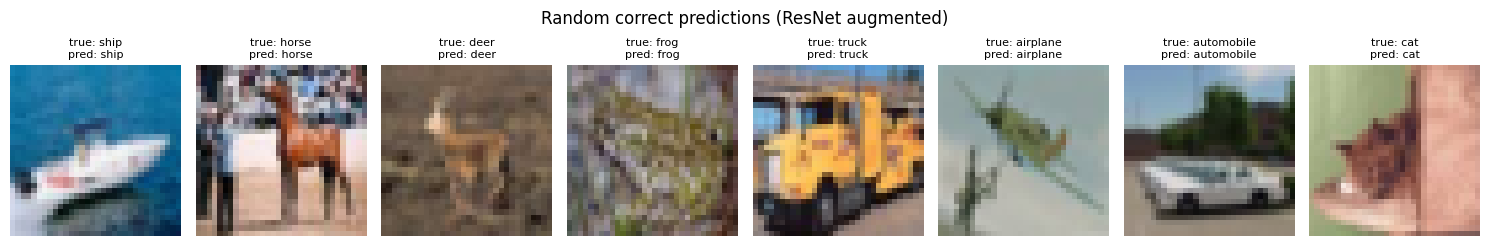

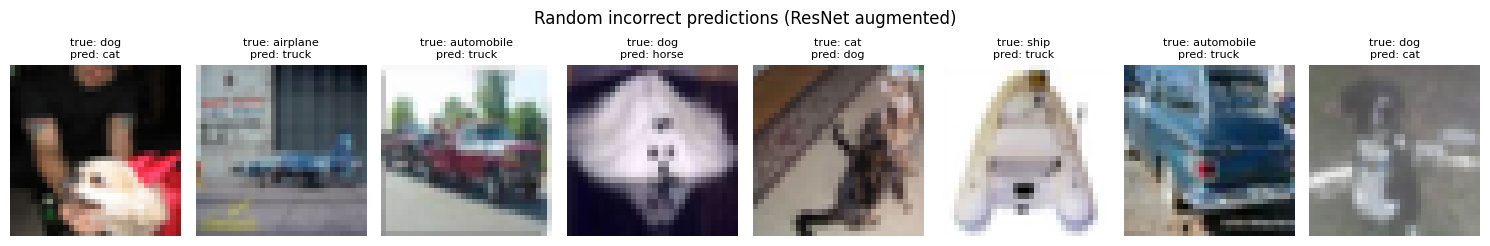

In [23]:
pred = np.array(predictions["ResNet augmented"]["pred"]); truth = np.array(predictions["ResNet augmented"]["truth"])
rng = np.random.default_rng(0)
correct_ids = rng.choice(np.flatnonzero(pred == truth), 8, replace=False)
wrong_ids = rng.choice(np.flatnonzero(pred != truth), 8, replace=False)
for ids, title in [(correct_ids, "Random correct predictions (ResNet augmented)"),
                   (wrong_ids, "Random incorrect predictions (ResNet augmented)")]:
    fig, axes = plt.subplots(1, 8, figsize=(15, 2.6))
    for ax, i in zip(axes, ids):
        ax.imshow(raw_test.data[i]); ax.axis("off")
        ax.set_title(f"true: {CLASS_NAMES[truth[i]]}\npred: {CLASS_NAMES[pred[i]]}", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

FGSM takes one step of size ε in the direction of the sign of the loss gradient. The budget is an L∞ bound in pixel units (ε = k/255), and the perturbed image is clipped to [0, 1]. The success rate is the share of correctly classified images, among the first 2,048 test images, whose prediction changes.

name,AlexNet baseline,ResNet augmented,ResNet baseline
epsilon_in_255,,,
1,0.2679,0.4194,0.3499
2,0.4976,0.6734,0.6355
4,0.7256,0.8264,0.8289
8,0.8012,0.8920,0.9328


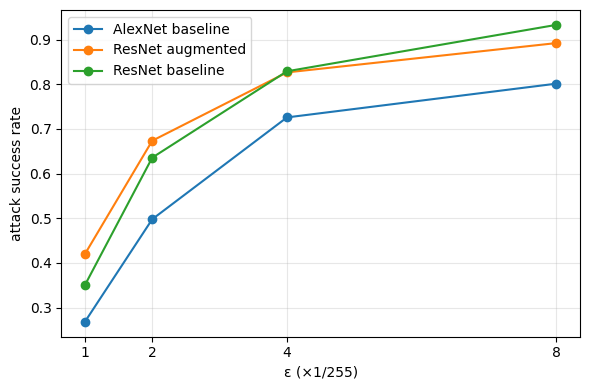

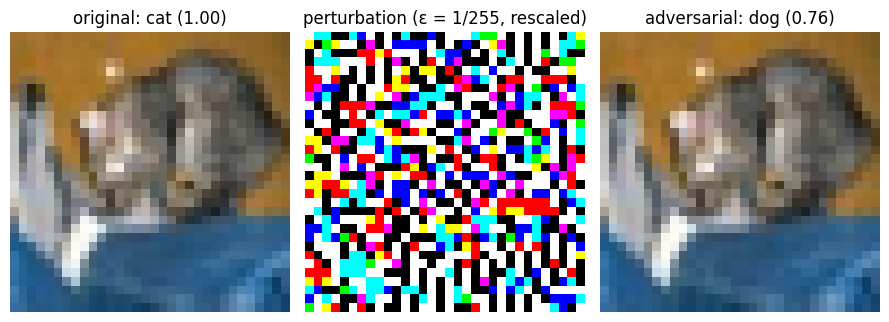

{'method': 'FGSM (single step, L-infinity, pixel space)', 'epsilon': 0.00392156862745098, 'epsilon_in_255': 1, 'test_index': 0, 'true_label': 3, 'original_prediction': 3, 'original_confidence': 0.9998084902763367, 'adversarial_prediction': 5, 'adversarial_confidence': 0.7557739615440369, 'attack_success': True}
Max absolute pixel change: 0.0039


In [24]:
display(adv_rates.pivot(index="epsilon_in_255", columns="name", values="success_rate"))
fig, ax = plt.subplots(figsize=(6, 4))
for name, g in adv_rates.groupby("name"):
    ax.plot(g.epsilon_in_255, g.success_rate, marker="o", label=name)
ax.set_xlabel("ε (×1/255)"); ax.set_ylabel("attack success rate"); ax.set_xticks([1, 2, 4, 8])
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

example = np.load(metrics / "adversarial_example.npz")
clean, adv = example["clean"].transpose(1, 2, 0), example["adversarial"].transpose(1, 2, 0)
delta = adv - clean
fig, axes = plt.subplots(1, 3, figsize=(9, 3.4))
axes[0].imshow(clean); axes[0].set_title(f"original: {CLASS_NAMES[adversarial['original_prediction']]} ({adversarial['original_confidence']:.2f})")
axes[1].imshow(0.5 + delta / (2 * np.abs(delta).max())); axes[1].set_title(f"perturbation (ε = {adversarial['epsilon_in_255']}/255, rescaled)")
axes[2].imshow(adv); axes[2].set_title(f"adversarial: {CLASS_NAMES[adversarial['adversarial_prediction']]} ({adversarial['adversarial_confidence']:.2f})")
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()
print(adversarial)
print("Max absolute pixel change:", np.abs(delta).max().round(4))

## Task 6. Cost and benchmark

Training time is wall-clock time for 30 epochs including validation after every epoch. Inference throughput is measured on one test batch of 512 images that is already on the device: five untimed warm-up passes, then twenty timed passes in float32 and eval mode, with CUDA synchronisation before and after the timed loop.

,seconds_per_epoch,inference_ms_per_batch,inference_images_per_second,best_validation_accuracy,test_accuracy,parameters_M,training_minutes,noise_accuracy,rotation_accuracy,fgsm_success_4/255
name,,,,,,,,,,
ResNet augmented,35.2539,203.9725,2510.1428,0.9144,0.9037,11.1740,17.6269,0.7228,0.7180,0.8264
ResNet baseline,28.8664,203.1834,2519.8911,0.8490,0.8374,11.1740,14.4332,0.7733,0.6588,0.8289
ResNet dropout 0.3,29.2944,204.1135,2508.4078,0.8422,0.8365,11.1740,14.6472,NaN,NaN,NaN
ResNet L2,28.6603,202.4802,2528.6428,0.8424,0.8351,11.1740,14.3301,NaN,NaN,NaN
AlexNet baseline,16.4055,33.5758,15249.0978,0.8260,0.8204,6.9768,8.2027,NaN,NaN,0.7256
ResNet dropout 0.5,29.0905,202.4028,2529.6094,0.8220,0.8174,11.1740,14.5452,NaN,NaN,NaN
ResNet width 32,18.0913,54.3676,9417.3763,0.8116,0.8125,2.7976,9.0456,NaN,NaN,NaN
ResNet width 16,16.2114,19.8618,25778.1457,0.7960,0.7978,0.7015,8.1057,NaN,NaN,NaN


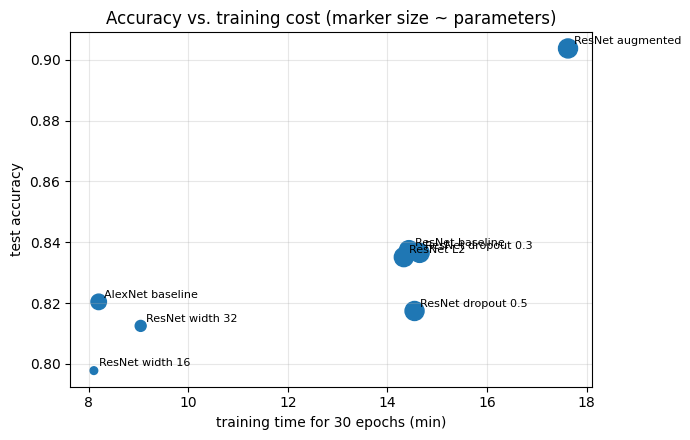

In [25]:
bench = model_results[["parameters", "seconds_per_epoch", "training_seconds", "inference_ms_per_batch",
                       "inference_images_per_second", "best_validation_accuracy", "test_accuracy"]].copy()
bench["parameters_M"] = bench.pop("parameters") / 1e6
bench["training_minutes"] = bench.pop("training_seconds") / 60
for name, row in robustness.iterrows():
    key = "ResNet baseline" if name == "ResNet basic" else name
    bench.loc[key, "noise_accuracy"] = row.noise_accuracy
    bench.loc[key, "rotation_accuracy"] = row.rotation_accuracy
fgsm4 = adv_rates[adv_rates.epsilon_in_255 == 4].set_index("name").success_rate
bench["fgsm_success_4/255"] = fgsm4
display(bench.sort_values("test_accuracy", ascending=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(bench.training_minutes, bench.test_accuracy, s=20 + 15 * bench.parameters_M)
for name, row in bench.iterrows():
    ax.annotate(name, (row.training_minutes, row.test_accuracy), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("training time for 30 epochs (min)"); ax.set_ylabel("test accuracy")
ax.set_title("Accuracy vs. training cost (marker size ~ parameters)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Saving the results

The cell below packs `outputs/metrics/` into one zip file so the results of a Colab run can be downloaded and added to the repository. Model checkpoints are kept in `outputs/checkpoints/` and are not included.

In [26]:
import shutil
archive = shutil.make_archive("id2223_lab1_metrics", "zip", OUTPUT_ROOT, "metrics")
print(archive)

/content/id2223_lab1_metrics.zip


## References

- A. Krizhevsky, *Learning Multiple Layers of Features from Tiny Images*, 2009. CIFAR-10: https://www.cs.toronto.edu/~kriz/cifar.html
- A. Krizhevsky, I. Sutskever and G. E. Hinton, *ImageNet Classification with Deep Convolutional Neural Networks*, NeurIPS 2012.
- K. He, X. Zhang, S. Ren and J. Sun, *Deep Residual Learning for Image Recognition*, CVPR 2016.
- I. J. Goodfellow, J. Shlens and C. Szegedy, *Explaining and Harnessing Adversarial Examples*, ICLR 2015.
- PyTorch and torchvision documentation: https://pytorch.org/docs/stable/ and https://pytorch.org/vision/stable/